# 01 Explore the dataset

**The dataset:** MixedWM38 is a file of wafer maps from Kaggle, about 38,000 by its description. A wafer map is a picture of one
silicon wafer after testing. It is a grid of 52 by 52, where every square one chip (a die). Each die passed or
failed the test. The failed dies make a pattern, like a ring or a scratch. Every map comes with an 8 digit label that says which patterns are on it.

**Explore first** The dataset comes with a description that makes claims: how many maps, what the numbers
mean, how many of each type.

**What this notebook does.** It opens the file, checks the shape, the values, the labels and the counts, looks for
missing values and copies, and draws one wafer of each pattern.

**In:** `data/Wafer_Map_Datasets.npz`
**Out:** nothing

## 1. Open the file and check the size

**Why this step:** If the data is not what I expect nothing after this step will work.

**How:** `np.load` opens the `.npz` file, which is a zip of NumPy arrays. Inside are two: `arr_0` with the maps and `arr_1` with the labels. I give them readable names, `maps` and `labels`.\
`.shape` gives the size of an array. For the maps it's three numbers: how many maps, how many rows, how many columns. For the labels it's two: how many labels, and how many numbers per label.\

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import wafer          # my own file with the shared functions: label_name, the 8 defect names

data = np.load("../data/Wafer_Map_Datasets.npz")
maps = data["arr_0"]      # The wafer maps
labels = data["arr_1"]    # The labels

# (how many maps, rows, columns)
print("Maps:", maps.shape, maps.dtype)

# (how many labels, numbers per label)
print("Labels:", labels.shape, labels.dtype)

Maps: (38015, 52, 52) int32
Labels: (38015, 8) int32


## 2. What do the numbers in a map mean?

**How:** The description says every square is 0 (no die, the empty corners around the round wafer), 1 (a good die) or 2 (a failed die).\
`np.unique(maps, return_counts=True)` goes through every square of every map and gives every different value once, plus how often it shows up. `zip(values, counts)` walks through both lists side by side, so I can print each value next to its count.

In [2]:
values, counts = np.unique(maps, return_counts=True)

for v, c in zip(values, counts):
    print(f"value {v}: {c:,} squares ") # Values the description names: 0, 1, 2

value 0: 24,349,490 squares 
value 1: 53,392,308 squares 
value 2: 25,050,548 squares 
value 3: 214 squares 


## 3. What does a label mean?

**Why this step:** The model has to give back a label in the same form (FR-01), and turn it into a name (FR-02).

**The problem:** Turn an 8 number label into something a person can read.

**How:** A label has one position per basic defect, always in this order: Center, Donut, Edge-Loc, Edge-Ring, Loc, Near-Full, Scratch, Random. A 1 means that defect is there. So `[0 1 0 0 0 0 1 0]` is Donut and Scratch.\
`wafer.label_name()` loops over the 8 positions and collects the names where there's a 1. All zeros gives "Normal".\
I pick 10 wafers at random with `rng.choice`, because the file is sorted by type the first 10 would all be the same. `np.random.default_rng(42)` makes a random number generator with seed 42.

In [3]:
rng = np.random.default_rng(42)
random_indices = rng.choice(len(labels), 10, replace=False)

for i in random_indices:
    print(f"wafer {i}: {labels[i]} - {wafer.label_name(labels[i])}")

print("The 8 positions, in order:", wafer.DEFECTS)

wafer 3266: [1 0 0 1 0 0 1 0] - Center + Edge-Ring + Scratch
wafer 29415: [0 0 0 1 1 0 1 0] - Edge-Ring + Loc + Scratch
wafer 3392: [1 0 0 1 0 0 1 0] - Center + Edge-Ring + Scratch
wafer 24878: [0 1 0 0 0 0 0 0] - Donut
wafer 16681: [0 1 0 1 0 0 0 0] - Donut + Edge-Ring
wafer 16458: [0 1 0 1 0 0 0 0] - Donut + Edge-Ring
wafer 26509: [0 0 0 1 0 0 0 0] - Edge-Ring
wafer 3580: [1 0 0 1 0 0 1 0] - Center + Edge-Ring + Scratch
wafer 7658: [1 0 0 1 1 0 1 0] - Center + Edge-Ring + Loc + Scratch
wafer 32636: [0 0 0 0 1 0 0 0] - Loc
The 8 positions, in order: ['Center', 'Donut', 'Edge-Loc', 'Edge-Ring', 'Loc', 'Near-Full', 'Scratch', 'Random']


## 4. How many wafers of each kind?

**Why this step:** If some patterns are rare the model only gets few examples of them, and we need every pattern to be present after the split.

**The problem:** Count the wafers in two ways: per defect, and per type.

**How:** **Per defect:** how many wafers have a particular defect. `labels[:, i]` takes column i, so one defect for all wafers. `== 1` makes it True/False and `.sum()` counts the Trues.\
**Per type:** how many wafers have exactly this combination of 8. `np.unique(labels, axis=0, return_counts=True)` does this: `axis=0` makes it compare whole rows, so every different row is one type.\
`np.argsort(counts)` gives the positions in order from smallest to biggest count, so I can print the smallest and the biggest types.

In [4]:
# Per defect: how many wafers have it somewhere
for i in range(len(wafer.DEFECTS)):
    count = (labels[:, i] == 1).sum()
    percent = count / len(labels) * 100
    print(f"{wafer.DEFECTS[i]}: {count:,} wafers ({percent:.1f}%)")

# Per type: every different label, and how many wafers have it
combos, combo_counts = np.unique(labels, axis=0, return_counts=True)
print("Different types:", len(combos), "(should bes 38)")
order = np.argsort(combo_counts)
print("Smallest types:")
for i in order[:3]: print(f"  {combo_counts[i]:,} - {wafer.label_name(combos[i])}")
print("Biggest type:")
print(f"  {combo_counts[order[-1]]:,} - {wafer.label_name(combos[order[-1]])}")

Center: 13,000 wafers (34.2%)
Donut: 12,000 wafers (31.6%)
Edge-Loc: 13,000 wafers (34.2%)
Edge-Ring: 12,000 wafers (31.6%)
Loc: 18,000 wafers (47.3%)
Near-Full: 149 wafers (0.4%)
Scratch: 19,000 wafers (50.0%)
Random: 866 wafers (2.3%)
Different types: 38 (should bes 38)
Smallest types:
  149 - Near-Full
  866 - Random
  1,000 - Normal
Biggest type:
  2,000 - Center + Edge-Loc + Scratch


## 5. Is anything missing?

**Why this step:** A missing or NaN value would break training later, and a label with a 2 in it would mean the labels are broken.

**How:** `.min()` and `.max()` give the smallest and biggest number in an array. `np.isnan()` is True wherever a number is missing. It only works on decimal numbers, so I turn the maps into decimals first with `.astype(float)`.

In [5]:
# What are the min/max pixel values?
print(f"maps: min {maps.min()}, max {maps.max()}")

# What are the min/max label values?
print(f"labels: min {labels.min()}, max {labels.max()}")

# How many NaNs exist?
print("missing values:", np.isnan(maps).sum())

maps: min 0, max 3
labels: min 0, max 1
missing values: 0


## 6. Are any maps in the file twice?

**Why this step:** If a wafer is in the training part and its exact copy is in the test part, the model is tested on something it already saw. The score comes out too high.

**The problem:** Find maps that are exactly the same, square for square.

**How:** `np.unique` can compare whole rows, but a map is a 52 by 52 grid. So first `maps.reshape(len(maps), -1)` flattens every map into one row of 2704 numbers. The -1 means "work this size out yourself".\
Then `np.unique(..., axis=0, return_index=True, return_counts=True)` gives every different map once, where it first appears and how many times.

In [6]:
# Flattens each wafer into a single row for comparison
maps_flat = maps.reshape(len(maps), -1)

# Find unique rows, where they first appear, and how often
unique_maps, first_index, times_seen = np.unique(maps_flat, axis=0, return_index=True, return_counts=True)

repeated = times_seen > 1
print(f"Maps in the file: {len(maps):,}")
print(f"Different maps: {len(unique_maps):,}")
print(f"Maps that are there more than once: {repeated.sum():,}")
print(f"Wafers involved: {times_seen[repeated].sum():,}")
print(f"Extra copies to remove: {len(maps) - len(unique_maps):,}")

Maps in the file: 38,015
Different maps: 36,991
Maps that are there more than once: 1,023
Wafers involved: 2,047
Extra copies to remove: 1,024


## 7. Which wafers are the copies?

**Why this step:** Cleaning the data, show one pair of identical maps, and count the extra copies per type.

**How:** `np.where(condition)[0]` gives the positions where something is True. `(maps_flat == one_map).all(axis=1)` compares every row with one map, and is only True where all 2704 squares match.\
For the count per type: every wafer that isn't the first of its map is an extra copy. `first_index` holds the first ones, so everything else is extra.

In [7]:
# All wafers that have the same map as the first repeated one
one_map = unique_maps[repeated][0]

same = np.where((maps_flat == one_map).all(axis=1))[0]
print("These wafers have the exact same map:", same)
for i in same:
    print(f"  wafer {i}: {wafer.label_name(labels[i])}")

# Every wafer that is not the first of its map is an extra copy
is_extra = np.ones(len(maps), dtype=bool)
is_extra[first_index] = False

print()
print("Extra copies per type:")
types_extra, counts_extra = np.unique(labels[is_extra], axis=0, return_counts=True)
for t, c in zip(types_extra, counts_extra):
    print(f"  {c} - {wafer.label_name(t)}")

These wafers have the exact same map: [ 280 1280]
  wafer 280: Center + Edge-Loc + Scratch
  wafer 1280: Center + Edge-Loc + Scratch

Extra copies per type:
  16 - Random
  8 - Near-Full
  1000 - Center + Edge-Loc + Scratch


## 8. Where are the wafers with a 3?

**Why this step:** I have to decide what to do with the value 3 (FR-04).
Knowing which wafers have it helps me decide.

**The problem:** Count the wafers that have a 3, and see which types they are.

**How:** `(maps == 3)` is True on every square with a 3. `.any(axis=(1, 2))` asks per wafer: is there at least one True across the rows and columns? So I get one True/False per wafer.

In [8]:
has_3 = (maps == 3).any(axis=(1, 2))

print("Wafers with a 3:", has_3.sum())
print("Squares with a 3:", (maps == 3).sum())

print("Which types:")
types_3, counts_3 = np.unique(labels[has_3], axis=0, return_counts=True)
for t, c in zip(types_3, counts_3):
    print(f"  {c} - {wafer.label_name(t)}")

Wafers with a 3: 105
Squares with a 3: 214
Which types:
  97 - Random
  8 - Near-Full


## 9. What do the patterns look like?

**Why this step:** Seeing the 8 patterns so you can see a Center sits in the middle and an Edge-Ring is a ring along the edge.

**The problem:** Draw one wafer of each basic pattern.

**How:** For each defect I make the label with only that position on 1, and find the first wafer with exactly that label. `plt.subplot(2, 4, i + 1)` picks box i + 1 in a grid of 2 rows and 4 columns, it counts from 1. `plt.imshow` draws an array as a picture, one colour per value: dark purple is no die, green is good, yellow is failed.

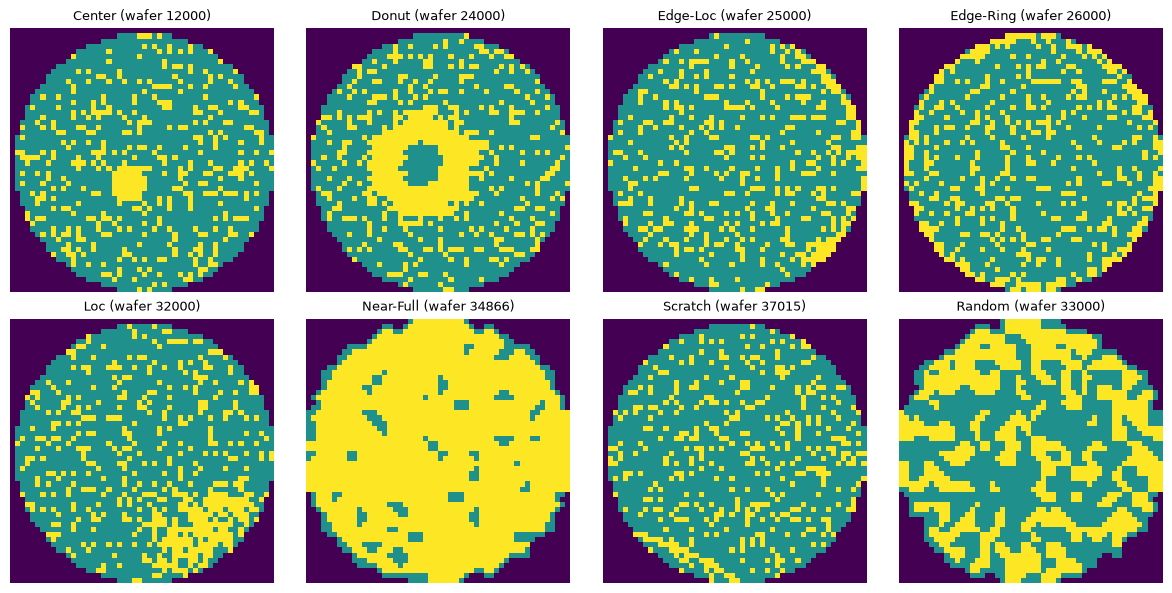

In [9]:
plt.figure(figsize=(12, 6))

for i in range(len(wafer.DEFECTS)):
    # The label with only this one defect
    wanted = np.zeros(8, dtype=labels.dtype)
    wanted[i] = 1
    found = np.where((labels == wanted).all(axis=1))[0]

    plt.subplot(2, 4, i + 1)
    plt.imshow(maps[found[0]])
    plt.title(f"{wafer.DEFECTS[i]} (wafer {found[0]})", fontsize=9)
    plt.axis("off")

plt.tight_layout()
plt.show()

## Functions in this notebook

| Function | What it does | Where to read more |
|---|---|---|
| `np.load` | opens a saved .npz file | [docs](https://numpy.org/doc/stable/reference/generated/numpy.load.html) |
| `np.unique` | every different value or row once, with counts and first positions | [docs](https://numpy.org/doc/stable/reference/generated/numpy.unique.html) |
| `np.argsort` | the positions in order from small to big | [docs](https://numpy.org/doc/stable/reference/generated/numpy.argsort.html) |
| `np.isnan` | True where a number is missing | [docs](https://numpy.org/doc/stable/reference/generated/numpy.isnan.html) |
| `.reshape` | gives an array a new shape, here one row per map | [docs](https://numpy.org/doc/stable/reference/generated/numpy.reshape.html) |
| `np.where` | the positions where something is True | [docs](https://numpy.org/doc/stable/reference/generated/numpy.where.html) |
| `.any / .all` | is at least one / is every value True | [docs](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.any.html) |
| `rng.choice` | picks random positions | [docs](https://numpy.org/doc/stable/reference/random/generated/numpy.random.Generator.choice.html) |
| `plt.subplot / plt.imshow` | a grid of pictures / draws an array as a picture | [docs](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) |